# Future City sensor data – exploration
Source: `data-1794095549194.csv` (long format: one row per sensor, per metric, per reading).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.width",200); pd.set_option("display.max_columns",30)
df = pd.read_csv("data-1794095549194.csv", parse_dates=["time"]).sort_values(["sensor_id","type","time"]).reset_index(drop=True)
print(df.shape); display(df.head()); display(df.dtypes); display(df.isna().sum().to_frame("nulls"))
print("exact duplicate rows:", df.duplicated().sum(), "| duplicate (sensor,type,time):", df.duplicated(["sensor_id","type","time"]).sum())

(192464, 7)


,time,sensor_id,name,longitude,latitude,type,value
0,2026-06-12 12:27:15.278588+00:00,00091a5f,hn-goetzentuem-01,9.214804,49.139958,batteryData,99.0
1,2026-06-17 16:36:01.940700+00:00,00091a5f,hn-goetzentuem-01,9.214804,49.139958,batteryData,17.0
2,2026-06-17 16:51:18.367311+00:00,00091a5f,hn-goetzentuem-01,9.214804,49.139958,batteryData,17.0
3,2026-06-17 17:21:52.954354+00:00,00091a5f,hn-goetzentuem-01,9.214804,49.139958,batteryData,17.0
4,2026-06-17 17:37:08.010567+00:00,00091a5f,hn-goetzentuem-01,9.214804,49.139958,batteryData,17.0


time         datetime64[us, UTC]
sensor_id                    str
name                         str
longitude                float64
latitude                 float64
type                         str
value                    float64
dtype: object

,nulls
time,0
sensor_id,0
name,0
longitude,0
latitude,0
type,0
value,0


exact duplicate rows: 0 | duplicate (sensor,type,time): 0


## 1. How many sensors, what date range?

In [2]:
meta = df.groupby("sensor_id").agg(name=("name","first"), n_names=("name","nunique"), lon=("longitude","first"), lat=("latitude","first"),
        n_locations=("latitude","nunique"), first=("time","min"), last=("time","max"), rows=("value","size"))
meta["days_active"] = (meta["last"]-meta["first"]).dt.total_seconds()/86400
print("sensors:", len(meta), "| distinct names:", df.name.nunique()); print("range:", df.time.min(), "->", df.time.max())
display(meta.sort_values("rows", ascending=False))
print("Names shared by several sensor_ids:", meta.name[meta.name.duplicated(keep=False)].unique())
print("metric types:", df.type.unique())

sensors: 12 | distinct names: 11
range: 2025-10-16 21:17:59.316153+00:00 -> 2026-11-07 23:51:57.342194+00:00


,name,n_names,lon,lat,n_locations,first,last,rows,days_active
sensor_id,,,,,,,,,
f8c19730,density-01,1,9.217465,49.143404,1,2026-04-16 23:25:31.573918+00:00,2026-11-07 23:48:49.164923+00:00,35170,205.016176
e52c55f3,hn-hagenbuchersee-01,1,9.217198,49.144402,1,2026-06-12 12:02:16.143036+00:00,2026-11-07 23:46:49.051578+00:00,24690,148.489270
ba71377f,hn-soleo-01,1,9.217393,49.144933,1,2026-06-12 11:52:36.889419+00:00,2026-11-07 23:32:32.859699+00:00,20654,148.486064
0f8519cf,hn-hagenbuchersee-02,1,9.216950,49.143910,1,2026-06-12 12:32:37.714826+00:00,2026-11-07 23:51:57.342194+00:00,20198,148.471755
00091a5f,hn-goetzentuem-01,1,9.214804,49.139958,1,2026-06-12 12:27:15.241799+00:00,2026-11-07 23:39:53.740331+00:00,19904,148.467112
d4cce74b,hn-neckarufer-01,1,9.216612,49.143313,1,2026-06-12 12:21:00.992399+00:00,2026-11-07 23:49:20.832221+00:00,19054,148.478007
8d7eef22,hn-marahaus-01,1,9.215912,49.141541,1,2026-06-12 12:36:14.714757+00:00,2026-11-07 23:49:35.315114+00:00,18508,148.467600
f4928534,hn-stadtgalerie-01,1,9.218699,49.140242,1,2026-06-12 12:11:38.733449+00:00,2026-11-07 23:26:29.605846+00:00,17964,148.468644
863f75b0,density-01,1,9.217473,49.143440,1,2025-10-16 21:17:59.316153+00:00,2026-03-12 18:28:06.042384+00:00,16150,146.882022


Names shared by several sensor_ids: <StringArray>
['density-01']
Length: 1, dtype: str
metric types: <StringArray>
['batteryData', 'densityData']
Length: 2, dtype: str


Note: `density-01` is used by **two** different `sensor_id`s with almost the same coordinates, so `sensor_id` (not `name`) must be the key. Several sensors have only a handful of rows (tests/demo devices such as `maker-fair`, `niklas-01`, `d3304b39`).

## 2. Sampling interval (5, 10 or 15 min?)

count    96220.000000
mean        21.796859
std        286.226271
min          0.085625
25%         15.270073
50%         15.309919
75%         16.130423
max      83380.400819
Name: dt_min, dtype: float64


,count
dt_min,
15.0,67328
16.0,18838
31.0,5668
46.0,786
30.0,748
32.0,569
61.0,214
17.0,190
18.0,110


,median_interval_min
sensor_id,
00091a5f,15.287712
062fe216,15.247067
0f8519cf,15.292855
2aadbeed,15.273263
863f75b0,15.182535
8d7eef22,15.275984
ba71377f,15.275610
d4cce74b,15.302074
e52c55f3,15.268059


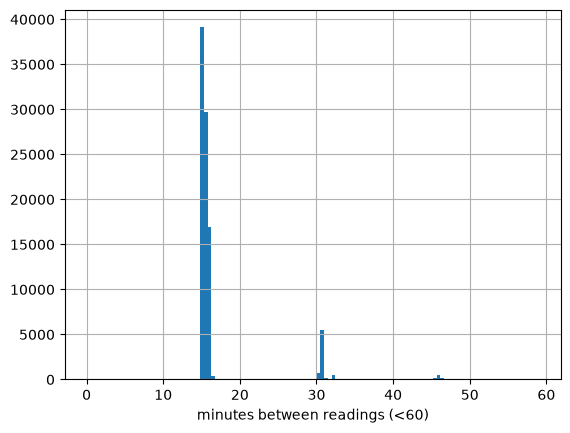

In [3]:
dens = df[df.type=="densityData"].copy()
dens["dt_min"] = dens.groupby("sensor_id").time.diff().dt.total_seconds()/60
print(dens.dt_min.describe())
display(dens.dt_min.round().value_counts().head(12).to_frame("count"))
display(dens[dens.dt_min.between(10,20)].groupby("sensor_id").dt_min.median().to_frame("median_interval_min"))
dens[dens.dt_min<60].dt_min.hist(bins=120); plt.xlabel("minutes between readings (<60)"); plt.show()

**Result:** the nominal interval is **~15 minutes** (median ≈ 15.3 min). The real spacing is 15 min + a few seconds of drift (16 min is common), so timestamps are *not* aligned to a clock grid and need bucketing (see §5).

## 3. Gaps – missing rows vs. real zeros

In [4]:
dens["gap_slots"] = (dens.dt_min/15).round().sub(1).clip(lower=0)
gaps = dens[dens.dt_min>20]   # >20 min = at least one missed reading
print("gaps >20 min:", len(gaps), "| missing 15-min slots:", int(gaps.gap_slots.sum()))
display(gaps.groupby("sensor_id").agg(n_gaps=("dt_min","size"), missing_slots=("gap_slots","sum"), longest_gap_h=("dt_min",lambda s:s.max()/60)))
display(gaps.nlargest(15,"dt_min")[["sensor_id","name","time","dt_min"]].assign(gap_days=lambda d:d.dt_min/1440))

# Coverage on a regular 15-min grid
dens["slot"] = dens.time.dt.floor("15min")
per = dens.groupby("sensor_id").slot.agg(["min","max","nunique"]).rename(columns={"nunique":"slots_with_data"})
per["expected"] = ((per["max"]-per["min"])/pd.Timedelta("15min")+1).astype(int)
per["coverage_%"] = (100*per.slots_with_data/per.expected).round(1)
display(per.sort_values("coverage_%"))

# Real zeros vs gaps
print("density == 0 rows:", (dens.value==0).sum(), f"({(dens.value==0).mean():.1%}) -> genuine 'nobody around' observations, kept as 0")

gaps >20 min: 9525 | missing 15-min slots: 40366


,n_gaps,missing_slots,longest_gap_h
sensor_id,,,
00091a5f,1225,4036.0,124.146296
062fe216,1,2.0,0.723217
0f8519cf,969,3925.0,101.520140
2aadbeed,4,216.0,38.099079
863f75b0,1830,5869.0,58.654426
8d7eef22,899,4789.0,152.327023
ba71377f,998,3680.0,102.404062
d3304b39,2,5969.0,1389.673347
d4cce74b,1225,4485.0,124.213397


,sensor_id,name,time,dt_min,gap_days
95584,d3304b39,hn-bollwerksturm-01,2026-08-13 16:00:50.846593+00:00,83380.400819,57.903056
69856,8d7eef22,hn-marahaus-01,2026-08-25 20:45:22.330593+00:00,9139.621383,6.346959
152107,f4928534,hn-stadtgalerie-01,2026-08-26 02:33:24.125050+00:00,8506.711850,5.907439
148313,f4928534,hn-stadtgalerie-01,2026-06-17 16:31:29.440086+00:00,7459.845111,5.180448
105114,d4cce74b,hn-neckarufer-01,2026-06-17 16:33:49.221417+00:00,7452.803817,5.175558
9953,00091a5f,hn-goetzentuem-01,2026-06-17 16:36:01.908631+00:00,7448.777781,5.172762
65670,8d7eef22,hn-marahaus-01,2026-06-17 16:37:39.890415+00:00,7440.953250,5.167329
70372,8d7eef22,hn-marahaus-01,2026-09-09 07:50:59.734451+00:00,7015.157989,4.871637
95583,d3304b39,hn-bollwerksturm-01,2026-06-16 18:20:26.797448+00:00,6178.751473,4.290800
85250,ba71377f,hn-soleo-01,2026-06-16 18:16:51.512928+00:00,6144.243725,4.266836


,min,max,slots_with_data,expected,coverage_%
sensor_id,,,,,
d3304b39,2026-06-12 11:15:00+00:00,2026-08-13 16:00:00+00:00,3,5972,0.1
2aadbeed,2026-08-13 16:00:00+00:00,2026-08-16 15:00:00+00:00,68,285,23.9
863f75b0,2025-10-16 21:15:00+00:00,2026-03-12 18:15:00+00:00,7967,14101,56.5
f4928534,2026-06-12 12:00:00+00:00,2026-11-07 23:15:00+00:00,8975,14254,63.0
8d7eef22,2026-06-12 12:30:00+00:00,2026-11-07 23:45:00+00:00,9253,14254,64.9
d4cce74b,2026-06-12 12:15:00+00:00,2026-11-07 23:45:00+00:00,9525,14255,66.8
00091a5f,2026-06-12 12:15:00+00:00,2026-11-07 23:30:00+00:00,9952,14254,69.8
0f8519cf,2026-06-12 12:30:00+00:00,2026-11-07 23:45:00+00:00,10098,14254,70.8
ba71377f,2026-06-12 11:45:00+00:00,2026-11-07 23:30:00+00:00,10326,14256,72.4


density == 0 rows: 4989 (5.2%) -> genuine 'nobody around' observations, kept as 0


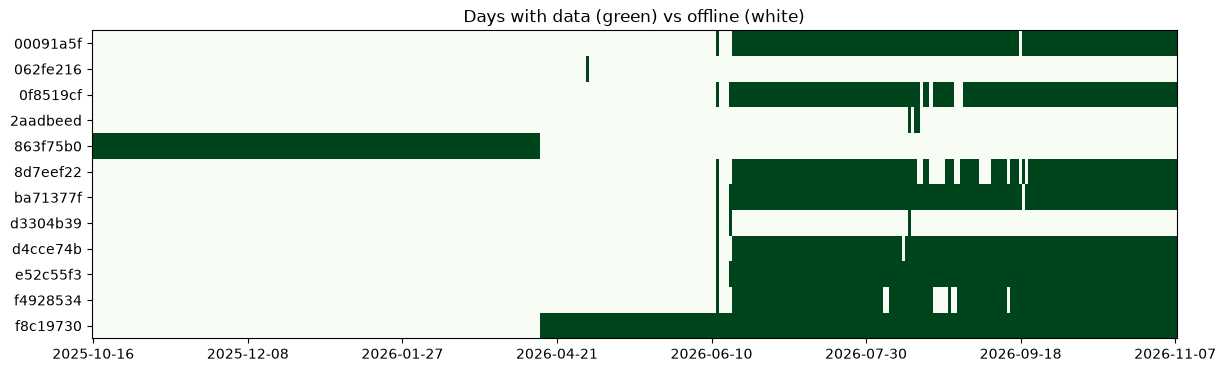

In [5]:
# Presence timeline: which days each sensor reported
d = dens.assign(day=dens.time.dt.floor("D")).groupby(["sensor_id","day"]).size().unstack(0)
fig,ax=plt.subplots(figsize=(14,4)); ax.imshow((d.notna()).T.astype(int), aspect="auto", cmap="Greens", interpolation="nearest")
ax.set_yticks(range(d.shape[1])); ax.set_yticklabels(d.columns); ax.set_title("Days with data (green) vs offline (white)")
ticks=np.linspace(0,len(d)-1,8).astype(int); ax.set_xticks(ticks); ax.set_xticklabels(d.index[ticks].strftime("%Y-%m-%d")); plt.show()

## 4. Outliers: spikes, stuck values, negatives

In [6]:
print("negative values by type:"); display(df[df.value<0].groupby("type").size().to_frame("n"))
display(df.groupby("type").value.describe(percentiles=[.5,.95,.99,.999]))
print("battery outside 0-100:", ((df.type=="batteryData")&~df.value.between(0,100)).sum())

negative values by type:


,n
type,


,count,mean,std,min,50%,95%,99%,99.9%,max
type,,,,,,,,,
batteryData,96232.0,25.729415,24.011687,0.0,17.0,75.0,78.0,89.0000,100.0
densityData,96232.0,13.289838,17.326230,0.0,7.7,46.9,78.4,158.7383,292.6


battery outside 0-100: 0


In [7]:
# Spikes: density vs. rolling median of its own sensor (robust z-score)
dens = dens.sort_values(["sensor_id","time"])
g = dens.groupby("sensor_id").value
dens["roll_med"] = g.transform(lambda s:s.rolling(9,center=True,min_periods=3).median())
dens["mad"] = (dens.value-dens.roll_med).abs().groupby(dens.sensor_id).transform(lambda s:s.rolling(97,center=True,min_periods=10).median())
dens["z"] = (dens.value-dens.roll_med)/(1.4826*dens.mad.replace(0,np.nan))
spikes = dens[(dens.z>8)&(dens.value>dens.roll_med+10)]
print("candidate spikes:", len(spikes)); display(spikes.nlargest(15,"value")[["sensor_id","name","time","value","roll_med","z"]])
print("top values:"); display(dens.nlargest(10,"value")[["sensor_id","time","value"]])

candidate spikes: 995


,sensor_id,name,time,value,roll_med,z
132339,e52c55f3,hn-hagenbuchersee-01,2026-08-14 19:19:06.811528+00:00,292.6,56.7,227.303386
127261,e52c55f3,hn-hagenbuchersee-01,2026-06-19 21:06:12.225773+00:00,262.5,233.1,28.328612
127173,e52c55f3,hn-hagenbuchersee-01,2026-06-18 21:07:51.419998+00:00,258.3,229.6,27.654121
105294,d4cce74b,hn-neckarufer-01,2026-06-19 19:53:59.650343+00:00,255.5,207.2,23.269931
127258,e52c55f3,hn-hagenbuchersee-01,2026-06-19 20:20:14.866732+00:00,252.7,233.1,18.885741
127259,e52c55f3,hn-hagenbuchersee-01,2026-06-19 20:35:29.881609+00:00,251.3,233.1,17.536760
105296,d4cce74b,hn-neckarufer-01,2026-06-19 20:40:18.896936+00:00,249.9,207.2,20.571968
127171,e52c55f3,hn-hagenbuchersee-01,2026-06-18 20:36:52.741472+00:00,246.4,229.6,16.187778
105295,d4cce74b,hn-neckarufer-01,2026-06-19 20:09:28.420875+00:00,235.9,207.2,13.827061
127350,e52c55f3,hn-hagenbuchersee-01,2026-06-20 20:17:46.016530+00:00,231.7,203.7,13.489815


top values:


,sensor_id,time,value
132339,e52c55f3,2026-08-14 19:19:06.811528+00:00,292.6
127261,e52c55f3,2026-06-19 21:06:12.225773+00:00,262.5
127173,e52c55f3,2026-06-18 21:07:51.419998+00:00,258.3
105294,d4cce74b,2026-06-19 19:53:59.650343+00:00,255.5
127258,e52c55f3,2026-06-19 20:20:14.866732+00:00,252.7
127259,e52c55f3,2026-06-19 20:35:29.881609+00:00,251.3
105296,d4cce74b,2026-06-19 20:40:18.896936+00:00,249.9
127171,e52c55f3,2026-06-18 20:36:52.741472+00:00,246.4
127262,e52c55f3,2026-06-19 21:21:27.205928+00:00,238.0
105295,d4cce74b,2026-06-19 20:09:28.420875+00:00,235.9


In [8]:
# Stuck values: same non-zero reading repeated >= 8 times in a row (zeros are legit at night, reported separately)
def runs(s):
    r = (s != s.shift()).cumsum(); return s.groupby(r).agg(val="first", n="size", start=lambda x:x.index[0], end=lambda x:x.index[-1])
out=[]
for (sid,t),grp in df.groupby(["sensor_id","type"]):
    s = grp.set_index("time").value; r = runs(s); r["sensor_id"]=sid; r["type"]=t; out.append(r)
R = pd.concat(out)
stuck = R[(R.n>=8)]
print("runs>=8 identical values, density non-zero:"); display(stuck[(stuck.type=="densityData")&(stuck.val!=0)].sort_values("n",ascending=False).head(15))
print("density zero-runs >=48 (12h) per sensor:"); display(stuck[(stuck.type=="densityData")&(stuck.val==0)&(stuck.n>=48)].sort_values("n",ascending=False).head(15))
print("battery flat runs (expected for plugged-in/solar):"); display(stuck[stuck.type=="batteryData"].sort_values("n",ascending=False).head(10))

runs>=8 identical values, density non-zero:


,val,n,start,end,sensor_id,type
value,,,,,,
5165,0.7,20,2026-09-29 22:48:44.233235+00:00,2026-09-30 03:39:30.265439+00:00,f4928534,densityData
5233,0.7,17,2026-09-30 23:17:47.968723+00:00,2026-10-01 03:53:13.423870+00:00,f4928534,densityData
8393,1.4,17,2026-11-04 00:31:44.377135+00:00,2026-11-04 04:51:51.295493+00:00,00091a5f,densityData
5755,0.7,16,2026-09-27 21:47:08.149286+00:00,2026-09-28 01:37:43.995942+00:00,00091a5f,densityData
5559,0.7,14,2026-10-05 23:40:50.096448+00:00,2026-10-06 03:45:39.060685+00:00,f4928534,densityData
3663,1.4,13,2026-09-01 22:14:17.032703+00:00,2026-09-02 01:18:48.484986+00:00,f4928534,densityData
4141,2.1,13,2026-06-10 22:56:01.358815+00:00,2026-06-11 02:09:41.549282+00:00,f8c19730,densityData
8131,0.7,12,2026-11-05 01:45:58.870433+00:00,2026-11-05 04:49:29.912045+00:00,8d7eef22,densityData
5497,0.7,12,2026-10-05 00:13:01.655044+00:00,2026-10-05 03:31:57.233443+00:00,f4928534,densityData


density zero-runs >=48 (12h) per sensor:


,val,n,start,end,sensor_id,type
value,,,,,,


battery flat runs (expected for plugged-in/solar):


,val,n,start,end,sensor_id,type
value,,,,,,
407,4.0,1832,2026-07-16 11:49:31.555252+00:00,2026-08-06 23:35:57.600406+00:00,0f8519cf,batteryData
1008,1.0,1118,2026-10-14 20:56:55.272498+00:00,2026-10-28 17:30:39.233269+00:00,f4928534,batteryData
1019,1.0,1104,2026-10-12 13:11:03.944890+00:00,2026-10-25 23:49:47.738166+00:00,00091a5f,batteryData
1264,4.0,1076,2026-09-15 00:07:35.073373+00:00,2026-10-04 04:15:30.440374+00:00,d4cce74b,batteryData
1719,2.0,1039,2026-10-24 22:40:53.703306+00:00,2026-11-06 00:57:57.811703+00:00,8d7eef22,batteryData
445,4.0,961,2026-07-24 09:56:28.251965+00:00,2026-08-04 09:19:03.575250+00:00,ba71377f,batteryData
1088,0.0,862,2026-10-28 16:52:05.185437+00:00,2026-11-07 23:39:53.740331+00:00,00091a5f,batteryData
1381,3.0,807,2026-10-10 19:10:02.895554+00:00,2026-10-20 06:10:16.456322+00:00,d4cce74b,batteryData
1434,2.0,772,2026-10-22 18:37:26.363625+00:00,2026-11-01 20:55:21.369436+00:00,d4cce74b,batteryData


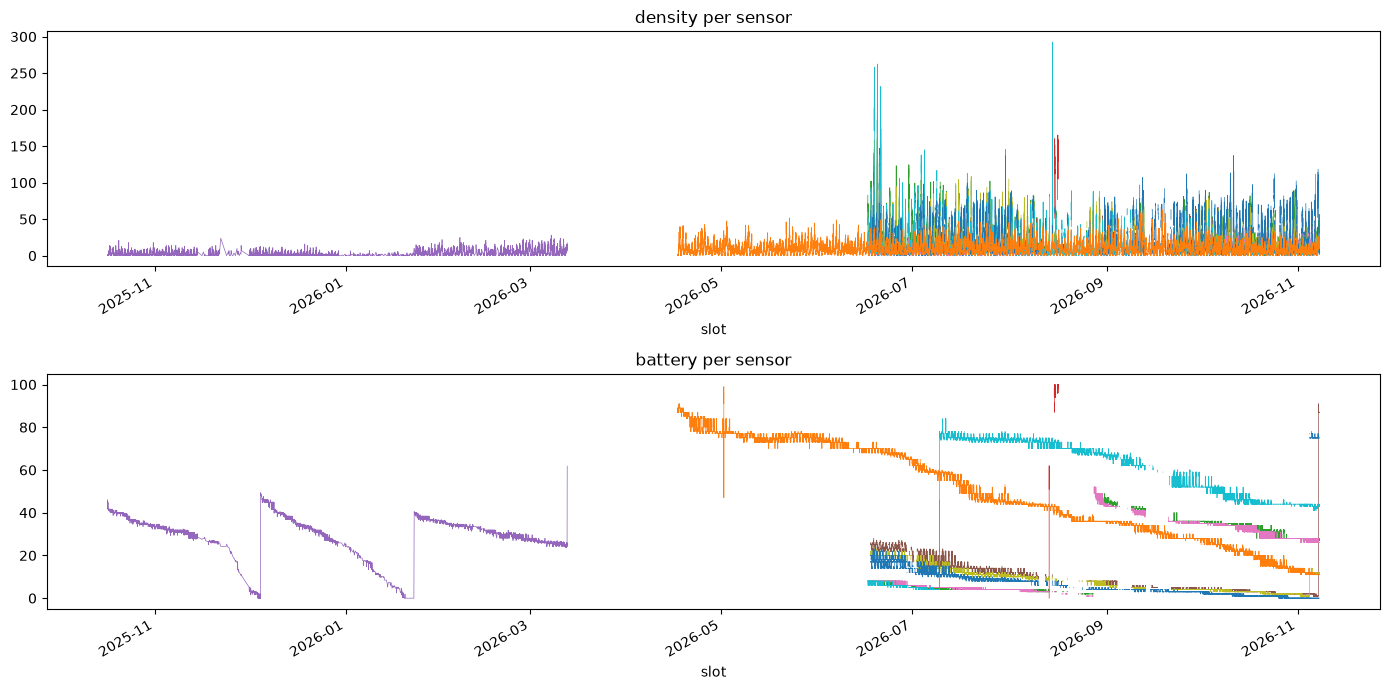

In [9]:
fig,ax=plt.subplots(2,1,figsize=(14,7))
dens.pivot_table(index="slot",columns="sensor_id",values="value").plot(ax=ax[0],legend=False,lw=.5,title="density per sensor")
b=df[df.type=="batteryData"].assign(slot=lambda d:d.time.dt.floor("15min")).pivot_table(index="slot",columns="sensor_id",values="value")
b.plot(ax=ax[1],legend=False,lw=.5,title="battery per sensor"); plt.tight_layout(); plt.show()

## 5. Time: timestamps

In [10]:
print("tz:", df.time.dt.tz, "| has sub-second precision:", (df.time.dt.microsecond>0).mean())
t = dens.time
print("hour-of-day distribution (UTC):"); display(t.dt.hour.value_counts().sort_index().to_frame("n").T)
print("minute-of-hour spread (is it clock aligned?):", t.dt.minute.nunique(), "distinct minutes")
# Battery and density stamped together?
dd = df[df.type=="densityData"][["sensor_id","time"]].reset_index(drop=True); bb = df[df.type=="batteryData"][["sensor_id","time"]].reset_index(drop=True)
m = pd.merge_asof(dd.sort_values("time"), bb.sort_values("time").rename(columns={"time":"btime"}), left_on="time", right_on="btime", by="sensor_id", direction="nearest")
print("density<->battery timestamp offset (s):"); display(((m.btime-m.time).abs().dt.total_seconds()).describe())
# Out-of-order / duplicate-second checks
print("duplicate timestamps per sensor+type:", df.duplicated(["sensor_id","type","time"]).sum(), "| same-slot double readings:", int(dens.duplicated(["sensor_id","slot"]).sum()))
print("DST note: timestamps are UTC, local is Europe/Berlin (Heilbronn) – convert only for display/aggregation by local day.")
local = t.dt.tz_convert("Europe/Berlin"); display(local.dt.hour.value_counts().sort_index().to_frame("n").T)

tz: UTC | has sub-second precision: 1.0
hour-of-day distribution (UTC):


time,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
n,4044,4000,4011,4026,4059,4109,4065,4001,4067,4001,3965,3969,3986,3938,3929,3881,3958,3958,3953,3986,4038,4065,4125,4098


minute-of-hour spread (is it clock aligned?): 60 distinct minutes
density<->battery timestamp offset (s):


count    96232.000000
mean         0.281824
std          1.263451
min          0.001390
25%          0.012680
50%          0.032699
75%          0.066989
max         34.286570
dtype: float64

duplicate timestamps per sensor+type: 0 | same-slot double readings: 129
DST note: timestamps are UTC, local is Europe/Berlin (Heilbronn) – convert only for display/aggregation by local day.


time,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
n,4120,4067,4032,4009,4017,4059,4068,4106,4047,4009,4064,4000,3964,3967,3997,3922,3944,3874,3952,3929,3987,3990,4040,4068


## 6. Findings → schema decisions
- Long format (`sensor_id, type, value`) stays; `name/lon/lat` are sensor attributes → move to `sensors` table (never repeat per row).
- `sensor_id` is the key (two sensors named `density-01`).
- Store **only rows that exist**; missing = no row. A regular 15-min grid is produced by a **view** that LEFT JOINs a generated series, so gaps surface as `NULL`, zeros stay `0`.
- Raw `value` is preserved; outlier handling is a separate `quality_flag`, not a destructive cleanup.
- Timestamps `timestamptz` (UTC), plus a `slot_15m` generated column for aligning drifted timestamps.

In [11]:
SCHEMA = """
-- PostgreSQL schema (generated from analysis.ipynb)
CREATE EXTENSION IF NOT EXISTS timescaledb;

CREATE TABLE sensors (
    sensor_id   text PRIMARY KEY,                      -- e.g. '863f75b0' (NOT unique per name!)
    name        text NOT NULL,
    longitude   double precision NOT NULL,
    latitude    double precision NOT NULL,
    first_seen  timestamptz,
    last_seen   timestamptz,
    is_test     boolean NOT NULL DEFAULT false         -- maker-fair, niklas-01, d3304b39 ... (few rows)
);

CREATE TYPE metric_type AS ENUM ('densityData','batteryData');

CREATE TABLE readings (
    time          timestamptz      NOT NULL,           -- UTC, original sub-second stamp
    sensor_id     text             NOT NULL REFERENCES sensors(sensor_id),
    type          metric_type      NOT NULL,
    value         double precision,                    -- NULL = unknown; never 0 as filler. 0 = real zero.
    slot_15m      timestamptz GENERATED ALWAYS AS (date_bin('15 minutes', time, TIMESTAMPTZ '2000-01-01 00:00:00+00')) STORED,
    quality_flag  smallint NOT NULL DEFAULT 0,         -- bit flags: 1=negative, 2=spike, 4=stuck, 8=out_of_range
    PRIMARY KEY (sensor_id, type, time),
    CONSTRAINT battery_range CHECK (type <> 'batteryData' OR value IS NULL OR value BETWEEN 0 AND 100)
);
CREATE INDEX readings_time_idx  ON readings (time);
CREATE INDEX readings_slot_idx  ON readings (type, slot_15m);
SELECT create_hypertable('readings','time', chunk_time_interval => interval '30 days');

-- Regular 15-minute grid: a missing slot appears as NULL (sensor offline), a real zero stays 0.
CREATE VIEW readings_15m AS
SELECT s.sensor_id, s.name, g.slot, m.type,
       avg(r.value) FILTER (WHERE r.quality_flag = 0) AS value,   -- NULL when no (clean) reading
       count(r.value)                                  AS n_readings
FROM sensors s
CROSS JOIN LATERAL generate_series(date_bin('15 minutes', s.first_seen, TIMESTAMPTZ '2000-01-01'),
                                   date_bin('15 minutes', s.last_seen,  TIMESTAMPTZ '2000-01-01'),
                                   interval '15 minutes') AS g(slot)
CROSS JOIN (VALUES ('densityData'::metric_type),('batteryData')) AS m(type)
LEFT JOIN readings r ON r.sensor_id = s.sensor_id AND r.type = m.type AND r.slot_15m = g.slot
GROUP BY s.sensor_id, s.name, g.slot, m.type;

-- Gap report: consecutive readings > 20 min apart
CREATE VIEW sensor_gaps AS
SELECT sensor_id, prev_time AS gap_start, time AS gap_end, time - prev_time AS gap_length
FROM (SELECT sensor_id, time, lag(time) OVER (PARTITION BY sensor_id ORDER BY time) AS prev_time
      FROM readings WHERE type='densityData') x
WHERE time - prev_time > interval '20 minutes';
"""
open("schema.sql","w").write(SCHEMA); print("wrote schema.sql")

# Load-ready extracts. Columns match the tables exactly; no gap is filled (missing slot = no row).
test_ids = meta.index[meta.rows < 200]
sensors_out = meta.reset_index()[["sensor_id","name","lon","lat","first","last"]]
sensors_out.columns = ["sensor_id","name","longitude","latitude","first_seen","last_seen"]
sensors_out["is_test"] = sensors_out.sensor_id.isin(test_ids)
sensors_out.to_csv("sensors_load.csv", index=False)
readings_out = df[["time","sensor_id","type","value"]].sort_values(["sensor_id","type","time"])
readings_out.to_csv("readings_load.csv", index=False, date_format="%Y-%m-%d %H:%M:%S.%f%z")
print(len(sensors_out),"sensors,",len(readings_out),"readings written"); display(readings_out.head(3)); display(sensors_out.head(3))
print("Load: \copy sensors(sensor_id,name,longitude,latitude,first_seen,last_seen,is_test) FROM sensors_load.csv CSV HEADER")
print("      \copy readings(time,sensor_id,type,value) FROM readings_load.csv CSV HEADER")


wrote schema.sql


<>:62: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:63: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:62: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:63: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
/tmp/ipykernel_298013/4267746560.py:62: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
  print("Load: \copy sensors(sensor_id,name,longitude,latitude,first_seen,last_seen,is_test) FROM sensors_load.csv CSV HEADER")
/tmp/ipykernel_298013/4267746560.py:63: SyntaxWarning: "\c" is an inv

12 sensors, 192464 readings written


,time,sensor_id,type,value
0,2026-06-12 12:27:15.278588+00:00,00091a5f,batteryData,99.0
1,2026-06-17 16:36:01.940700+00:00,00091a5f,batteryData,17.0
2,2026-06-17 16:51:18.367311+00:00,00091a5f,batteryData,17.0


,sensor_id,name,longitude,latitude,first_seen,last_seen,is_test
0,00091a5f,hn-goetzentuem-01,9.214804,49.139958,2026-06-12 12:27:15.241799+00:00,2026-11-07 23:39:53.740331+00:00,False
1,062fe216,niklas-01,9.149705,49.223918,2026-05-01 17:19:43.603332+00:00,2026-05-01 19:06:51.407202+00:00,True
2,0f8519cf,hn-hagenbuchersee-02,9.216950,49.143910,2026-06-12 12:32:37.714826+00:00,2026-11-07 23:51:57.342194+00:00,False


Load: \copy sensors(sensor_id,name,longitude,latitude,first_seen,last_seen,is_test) FROM sensors_load.csv CSV HEADER
      \copy readings(time,sensor_id,type,value) FROM readings_load.csv CSV HEADER
